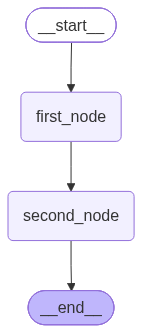

In [5]:
from typing import TypedDict
from langgraph.graph import StateGraph

# Define State
class AgentState(TypedDict):
    name : str
    age : str
    final : str

# Create nodes
def first_node(state: AgentState) -> AgentState:
    """This is the first node of our sequence"""
    state["final"] = f"Hi {state["name"]}"
    return state

def second_node(state: AgentState) -> AgentState:
    """This is the second node of the sequence"""
    state["final"] += f", your age is {state["age"]}"
    return state

# Create Graph
graph = StateGraph(AgentState)

# Add Nodes
graph.add_node("first_node",first_node)
graph.add_node("second_node",second_node)

#Add Edges
graph.set_entry_point("first_node")
graph.add_edge("first_node","second_node") # This is a directed edge
graph.set_finish_point("second_node")

# Compile Graph
app = graph.compile()

# Image
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))

In [6]:
result = app.invoke({"name":"Charlie","age":30})
print(result)

{'name': 'Charlie', 'age': 30, 'final': 'Hi Charlie, your age is 30'}


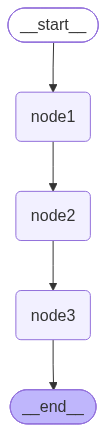

In [8]:
from typing import List

# State
class ProcessState(TypedDict):
    name : str
    age :str
    skills : List[str]
    result : str

# nodes

def node1(state: ProcessState) -> ProcessState:
    state["result"] = f"Hi {state["name"]}"
    return state
def node2(state: ProcessState) -> ProcessState:
    state["result"] += f", age : {state["age"]},"
    return state
def node3(state: ProcessState) -> ProcessState:
    state["result"] += ", skills :"
    for skill in state["skills"]:
        state["result"] += f"{skill},"
    return state

# Graph
graph = StateGraph(ProcessState)

# Nodes
graph.add_node("node1",node1)
graph.add_node("node2",node2)
graph.add_node("node3",node3)

# Add Edges
graph.set_entry_point("node1")
graph.add_edge("node1","node2")
graph.add_edge("node2","node3")
graph.set_finish_point("node3")

# Compile Graph
app = graph.compile()

# Image
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))


In [9]:
result = app.invoke({"name": "Charlie", "age": 30,"skills":["C#","ASP.NET","MongoDB"]})
print(result)

{'name': 'Charlie', 'age': 30, 'skills': ['C#', 'ASP.NET', 'MongoDB'], 'result': 'Hi Charlie, age : 30,, skills :C#,ASP.NET,MongoDB,'}
